# Final Figures

Assembles the final final figures and tables from the saved analysis outputs.


In [93]:
from collections import defaultdict
import csv
import importlib
from pathlib import Path
import sys

from IPython.display import Markdown, display
import matplotlib.pyplot as plt

# Resolve paths whether the notebook is launched from the repository root or from this folder.
working_directory = Path.cwd().resolve()
PROJECT_DIRECTORY = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

RESULTS_DIRECTORY = PROJECT_DIRECTORY / "results"
OUTPUT_DIRECTORY = RESULTS_DIRECTORY / "final_figures"

print("Project directory:", PROJECT_DIRECTORY)
print("Source directory:", SOURCE_DIRECTORY)
print("Saved results directory:", RESULTS_DIRECTORY)
print("Final figure output directory:", OUTPUT_DIRECTORY)

Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential
Source directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/src
Saved results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results
Final figure output directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/final_figures


## Settings

`RUN_SCOPE` is fixed to `"full"` for final figures. The input paths below point to saved result summaries produced by the earlier notebooks. Running this notebook only reads those summaries and writes regenerated figures to `OUTPUT_DIRECTORY`.

In [94]:
RUN_SCOPE = "full"

COMPACT_DATASETS = ("compact_benchmark_1d", "compact_benchmark_2d")
EXPANDED_DATASETS = ("benchmark_1d", "benchmark_2d")

COMPACT_SURROGATE_ROOT = RESULTS_DIRECTORY / "cmp_compact"
COMPACT_ACTUAL_ROOT = RESULTS_DIRECTORY / "actual_error"
EXPANDED_SURROGATE_ROOT = RESULTS_DIRECTORY / "cmp_extended"
ACTUAL_OPTIMAL_ROOT = RESULTS_DIRECTORY / "actual_optimal"

ACTUAL_OPTIMAL_SAMPLE_SCOPE = (
    "test_k3-4_m3-4_replicate_1"
    if RUN_SCOPE == "test"
    else "full_k3-4_m3-4_replicate_3"
)
ABLATION_TABLES_DIRECTORY = (
    EXPANDED_SURROGATE_ROOT
    / f"summary_heuristic_ablation_{RUN_SCOPE}"
    / "tables"
)

SAVE_FIGURES = True
DISPLAY_FIGURES = True

print("Run scope:", RUN_SCOPE)
print("Compact surrogate results:", COMPACT_SURROGATE_ROOT)
print("Compact actual-error results:", COMPACT_ACTUAL_ROOT)
print("Expanded surrogate results:", EXPANDED_SURROGATE_ROOT)
print("Actual-optimality results:", ACTUAL_OPTIMAL_ROOT)
print("Actual-optimality sample scope:", ACTUAL_OPTIMAL_SAMPLE_SCOPE)
print("Ablation tables:", ABLATION_TABLES_DIRECTORY)
print("Save figures:", SAVE_FIGURES)
print("Display figures inline:", DISPLAY_FIGURES)


Run scope: full
Compact surrogate results: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/cmp_compact
Compact actual-error results: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/actual_error
Expanded surrogate results: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/cmp_extended
Actual-optimality results: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/actual_optimal
Actual-optimality sample scope: full_k3-4_m3-4_replicate_3
Ablation tables: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/cmp_extended/summary_heuristic_ablation_full/tables
Save figures: True
Display figures inline: True


## Plot Style

The method colors follow the same restrained blue, orange, red, gray, and green palette used for the final final figures. Curves are also distinguished by line style and marker shape, so the figures remain readable in grayscale or black-and-white printouts.

In [95]:
import plot_style
plot_style = importlib.reload(plot_style)
plot_style.configure_plot_style()

BASE_METHOD_STYLES = plot_style.METHOD_STYLES
METHOD_STYLES = {
    "optimal": {"label": "Exhaustive", **BASE_METHOD_STYLES["Exhaustive"]},
    "greedy": {"label": "Greedy", **BASE_METHOD_STYLES["Greedy"]},
    "heuristic": {"label": "Heuristic", **BASE_METHOD_STYLES["Heuristic"]},
    "uniform": {"label": "Uniform", **BASE_METHOD_STYLES["Uniform"]},
    "random": {"label": "Random", **BASE_METHOD_STYLES["Random"]},
}

COMPACT_METHODS = ("optimal", "greedy", "heuristic", "uniform", "random")
EXPANDED_METHODS = ("greedy", "heuristic", "uniform", "random")

DIMENSION_LABELS = {1: "(a) One-dimensional data set", 2: "(b) Two-dimensional data set"}


## Load Saved Results

This section loads the saved full-result summary CSV files. It intentionally avoids the experiment-running functions used by the earlier notebooks.

In [96]:
def read_summary_csv(path):
    if not path.is_file():
        raise FileNotFoundError(f"Missing saved result table: {path}")
    with path.open("r", encoding="utf-8-sig", newline="") as input_file:
        return list(csv.DictReader(input_file))


def result_dataset_name(dataset):
    if dataset.startswith("compact_benchmark_"):
        return dataset.replace("compact_benchmark_", "compact_", 1)
    if dataset.startswith("benchmark_"):
        return dataset.replace("benchmark_", "extended_", 1)
    return dataset


def compact_surrogate_path(dataset):
    return COMPACT_SURROGATE_ROOT / f"{result_dataset_name(dataset)}_{RUN_SCOPE}" / "tables" / "summary.csv"


def compact_actual_path(dataset):
    return COMPACT_ACTUAL_ROOT / f"{result_dataset_name(dataset)}_{RUN_SCOPE}" / "tables" / "summary.csv"


def expanded_surrogate_path(dataset):
    return EXPANDED_SURROGATE_ROOT / f"{result_dataset_name(dataset)}_{RUN_SCOPE}" / "tables" / "summary.csv"


def actual_optimal_path(dataset):
    return ACTUAL_OPTIMAL_ROOT / f"{result_dataset_name(dataset)}_{ACTUAL_OPTIMAL_SAMPLE_SCOPE}" / "tables" / "summary.csv"


def ablation_budget_path():
    return ABLATION_TABLES_DIRECTORY / "budget_summary.csv"


compact_surrogate_records = {
    dataset: read_summary_csv(compact_surrogate_path(dataset))
    for dataset in COMPACT_DATASETS
}
compact_actual_records = {
    dataset: read_summary_csv(compact_actual_path(dataset))
    for dataset in COMPACT_DATASETS
}
expanded_surrogate_records = {
    dataset: read_summary_csv(expanded_surrogate_path(dataset))
    for dataset in EXPANDED_DATASETS
}
actual_optimal_records = {
    dataset: read_summary_csv(actual_optimal_path(dataset))
    for dataset in COMPACT_DATASETS
}
ablation_budget_rows = read_summary_csv(ablation_budget_path())

for label, grouped_records in (
    ("compact surrogate", compact_surrogate_records),
    ("compact actual", compact_actual_records),
    ("expanded surrogate", expanded_surrogate_records),
    ("actual-optimality", actual_optimal_records),
):
    print(label)
    for dataset, records in grouped_records.items():
        dimension = int(records[0]["spatial_dimension"])
        print(f"  {dataset}: {len(records)} rows, {dimension}D")
print("ablation budget rows:", len(ablation_budget_rows))


compact surrogate
  compact_benchmark_1d: 9996 rows, 1D
  compact_benchmark_2d: 10019 rows, 2D
compact actual
  compact_benchmark_1d: 9996 rows, 1D
  compact_benchmark_2d: 10019 rows, 2D
expanded surrogate
  benchmark_1d: 10728 rows, 1D
  benchmark_2d: 10732 rows, 2D
actual-optimality
  compact_benchmark_1d: 143 rows, 1D
  compact_benchmark_2d: 143 rows, 2D
ablation budget rows: 8


## Helper Functions

These utilities aggregate saved rows into the numerical values plotted in each figure. The aggregation is by budget ratio, pooling over the saved problem instances exactly as recorded in the result tables.

In [97]:
def value(row, key):
    return float(row[key])


def integer(row, key):
    return int(float(row[key]))


def mean(values):
    values = list(values)
    if not values:
        raise ValueError("Cannot take the mean of an empty collection")
    return sum(values) / len(values)


def by_dimension(records_by_dataset):
    return sorted(
        records_by_dataset.values(),
        key=lambda records: integer(records[0], "spatial_dimension"),
    )


def available_methods(records, requested_methods, suffix):
    sample = records[0]
    return [method for method in requested_methods if f"{method}{suffix}" in sample]


def curve_rows(records, methods, suffix):
    rows = []
    active_methods = available_methods(records, methods, suffix)
    budget_levels = sorted({integer(row, "budget_level") for row in records})
    for level in budget_levels:
        selected = [row for row in records if integer(row, "budget_level") == level]
        base = {
            "dimension": f"{integer(selected[0], 'spatial_dimension')}D",
            "budget_level": level,
            "budget_ratio": mean(value(row, "budget_fraction_of_N_min") for row in selected),
            "runs": len(selected),
        }
        for method in active_methods:
            base[f"{method}{suffix}"] = mean(value(row, f"{method}{suffix}") for row in selected)
        rows.append(base)
    return rows


def markdown_table(rows, columns, formats):
    header = "| " + " | ".join(label for label, _ in columns) + " |"
    separator = "|" + "|".join("---:" if key in formats else "---" for _, key in columns) + "|"
    body = []
    for row in rows:
        values = []
        for _, key in columns:
            formatter = formats.get(key)
            values.append(formatter(row[key]) if formatter else str(row[key]))
        body.append("| " + " | ".join(values) + " |")
    return "\n".join([header, separator, *body])


def save_figure(figure, filename):
    if not SAVE_FIGURES:
        return
    OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
    figure.savefig(OUTPUT_DIRECTORY / f"{filename}.pdf", bbox_inches="tight")
    figure.savefig(OUTPUT_DIRECTORY / f"{filename}.png", dpi=600, bbox_inches="tight")


def display_or_close(figure):
    if DISPLAY_FIGURES:
        display(figure)
    else:
        plt.close(figure)


def style_axis(axis):
    axis.grid(alpha=0.22, linewidth=0.8)
    axis.set_axisbelow(True)


def add_shared_legend(figure, axes, methods, *, ncol=None):
    handles = []
    labels = []
    for method in methods:
        style = METHOD_STYLES[method]
        handle = plt.Line2D(
            [0], [0],
            color=style["color"],
            linestyle=style["linestyle"],
            marker=style["marker"],
            linewidth=1.8,
            markersize=5.0,
        )
        handles.append(handle)
        labels.append(style["label"])
    figure.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=ncol or len(methods),
        frameon=False,
    )

## Figure 1: Compact Surrogate-Error Performance

This figure uses the saved compact exact-comparison results. The exhaustive curve is the surrogate-optimal reference produced during the original run; the other curves show the saved Greedy, Allocation + tree heuristic, Uniform, and Random solutions evaluated with the same surrogate objective.

### Figure Data: Compact Surrogate-Error Curves

| Dimension | Budget level | Budget ratio | Exhaustive | Greedy | Heuristic | Uniform | Random |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1D | 1 | 0.180 | 0.2951 | 0.3317 | 0.3034 | 0.5407 | 0.4894 |
| 1D | 2 | 0.337 | 0.1393 | 0.1705 | 0.1517 | 0.4049 | 0.3579 |
| 1D | 3 | 0.502 | 0.0708 | 0.1001 | 0.0808 | 0.2906 | 0.2606 |
| 1D | 4 | 0.639 | 0.0425 | 0.0694 | 0.0491 | 0.2214 | 0.2047 |
| 2D | 1 | 0.165 | 0.3365 | 0.3702 | 0.3443 | 0.5611 | 0.5204 |
| 2D | 2 | 0.308 | 0.1761 | 0.2060 | 0.1892 | 0.4394 | 0.3988 |
| 2D | 3 | 0.460 | 0.0997 | 0.1287 | 0.1110 | 0.3305 | 0.3059 |
| 2D | 4 | 0.585 | 0.0655 | 0.0934 | 0.0741 | 0.2591 | 0.2448 |

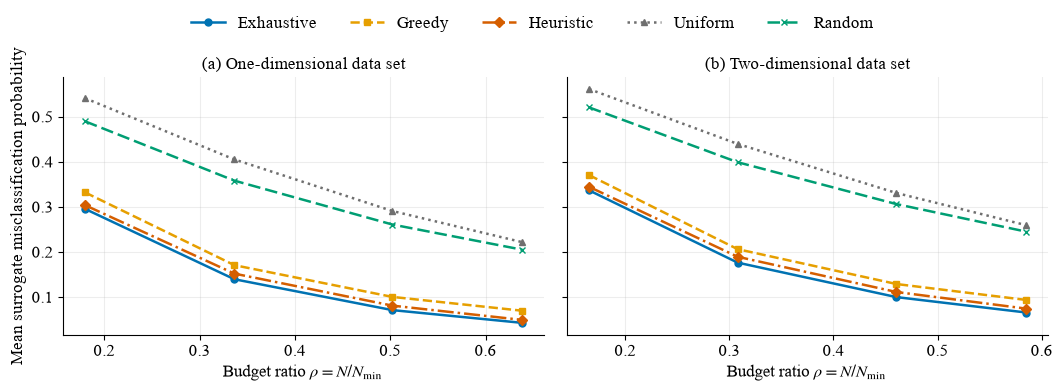

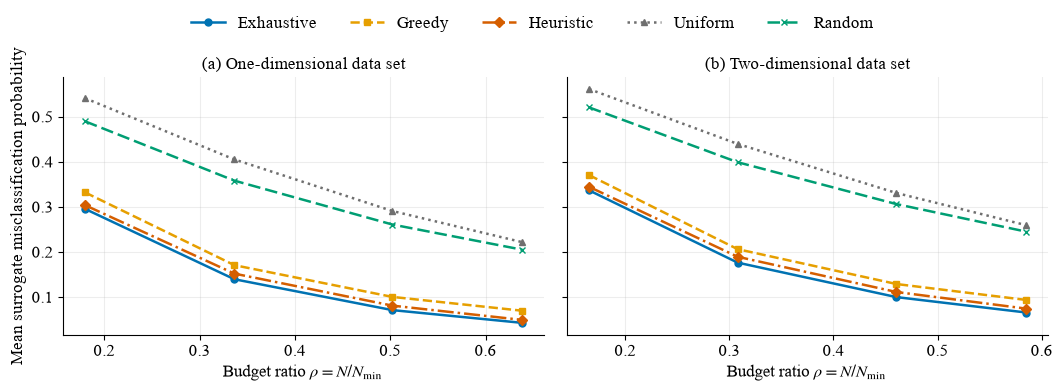

In [98]:
def plot_compact_surrogate_curves(records_by_dataset):
    figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.0), sharey=True)
    methods = COMPACT_METHODS
    for axis, records in zip(axes, by_dimension(records_by_dataset)):
        dimension = integer(records[0], "spatial_dimension")
        rows = curve_rows(records, methods, "_error")
        for method in methods:
            y_key = f"{method}_error"
            if y_key not in rows[0]:
                continue
            style = METHOD_STYLES[method]
            axis.plot(
                [row["budget_ratio"] for row in rows],
                [row[y_key] for row in rows],
                color=style["color"],
                linestyle=style["linestyle"],
                marker=style["marker"],
                linewidth=1.8,
                markersize=5.0,
                label=style["label"],
            )
        axis.set_title(DIMENSION_LABELS[dimension])
        axis.set_xlabel("Budget ratio $\\rho=N/N_{\\min}$")
        style_axis(axis)
    axes[0].set_ylabel("Mean surrogate misclassification probability")
    add_shared_legend(figure, axes, methods)
    figure.tight_layout(rect=(0, 0, 1, 0.90))
    return figure

compact_surrogate_curve_rows = [
    row
    for records in by_dimension(compact_surrogate_records)
    for row in curve_rows(records, COMPACT_METHODS, "_error")
]
display(Markdown("### Figure Data: Compact Surrogate-Error Curves"))
display(Markdown(markdown_table(
    compact_surrogate_curve_rows,
    (
        ("Dimension", "dimension"),
        ("Budget level", "budget_level"),
        ("Budget ratio", "budget_ratio"),
        ("Exhaustive", "optimal_error"),
        ("Greedy", "greedy_error"),
        ("Heuristic", "heuristic_error"),
        ("Uniform", "uniform_error"),
        ("Random", "random_error"),
    ),
    {
        "budget_level": lambda x: f"{int(x)}",
        "budget_ratio": lambda x: f"{float(x):.3f}",
        "optimal_error": lambda x: f"{float(x):.4f}",
        "greedy_error": lambda x: f"{float(x):.4f}",
        "heuristic_error": lambda x: f"{float(x):.4f}",
        "uniform_error": lambda x: f"{float(x):.4f}",
        "random_error": lambda x: f"{float(x):.4f}",
    },
)))

figure_1 = plot_compact_surrogate_curves(compact_surrogate_records)
save_figure(figure_1, "figure_1_compact_surrogate_error_curves")
display_or_close(figure_1)

## Figure 2: Surrogate Error Versus Actual Error

This validation figure uses the saved actual-error evaluation tables. The x-axis is the surrogate tree error computed with the 0.5/0.5 outside-pair rule, and the y-axis is the actual end-to-end error from the saved Helstrom branch-probability evaluation. Points close to the dashed line indicate agreement between the surrogate and the physical decision-tree calculation.

### Figure Data: Surrogate-Actual Error Differences

| Dimension | Method | Mean |Actual - Surrogate| | Maximum |Actual - Surrogate| |
|---|---|---:|---:|
| 1D | Exhaustive | 0.0466 | 0.2577 |
| 1D | Greedy | 0.0378 | 0.2352 |
| 1D | Heuristic | 0.0441 | 0.2439 |
| 1D | Uniform | 0.0189 | 0.1938 |
| 1D | Random | 0.0307 | 0.2241 |
| 2D | Exhaustive | 0.0504 | 0.2647 |
| 2D | Greedy | 0.0386 | 0.2317 |
| 2D | Heuristic | 0.0475 | 0.2551 |
| 2D | Uniform | 0.0162 | 0.2022 |
| 2D | Random | 0.0277 | 0.2265 |

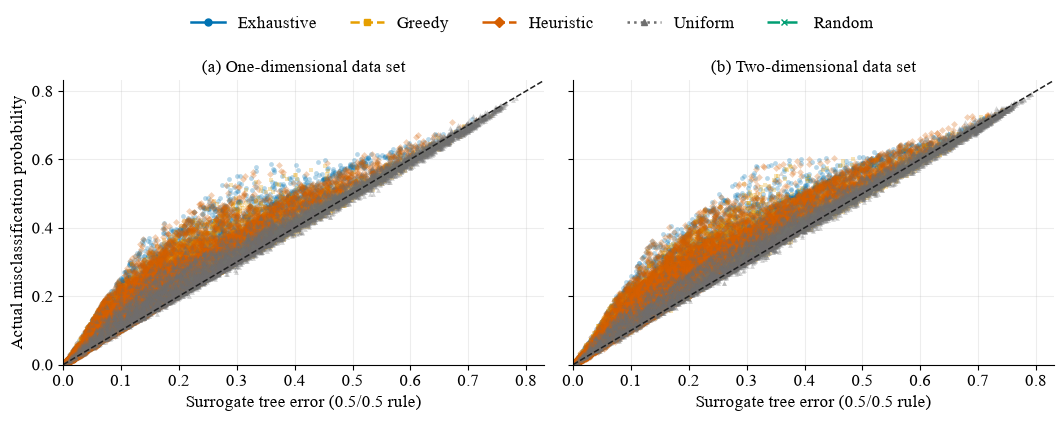

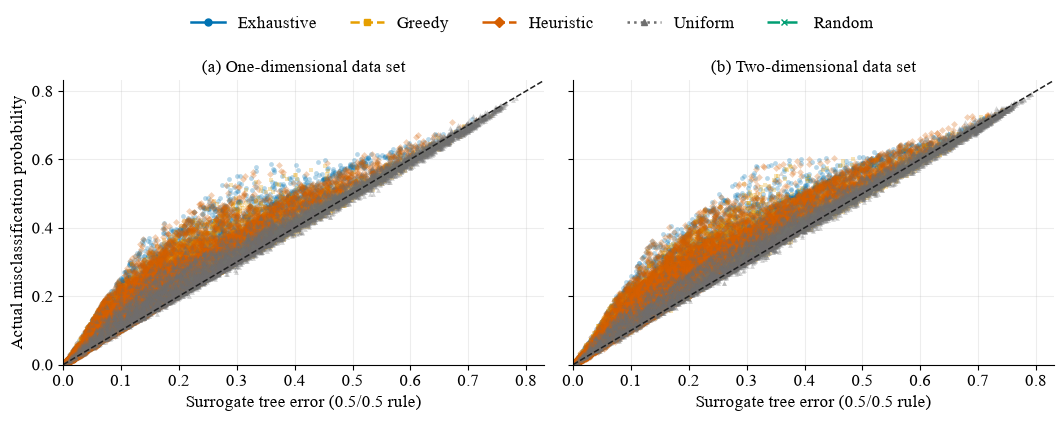

In [99]:
def plot_surrogate_actual_validation(records_by_dataset):
    figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.3), sharex=True, sharey=True)
    methods = COMPACT_METHODS
    maximum_value = 0.0
    for records in records_by_dataset.values():
        for method in available_methods(records, methods, "_actual_error"):
            maximum_value = max(
                maximum_value,
                max(value(row, f"{method}_error") for row in records),
                max(value(row, f"{method}_actual_error") for row in records),
            )
    limit = min(1.0, maximum_value * 1.04)

    for axis, records in zip(axes, by_dimension(records_by_dataset)):
        dimension = integer(records[0], "spatial_dimension")
        active_methods = available_methods(records, methods, "_actual_error")
        for method in active_methods:
            style = METHOD_STYLES[method]
            axis.scatter(
                [value(row, f"{method}_error") for row in records],
                [value(row, f"{method}_actual_error") for row in records],
                s=12,
                alpha=0.28,
                color=style["color"],
                marker=style["marker"],
                linewidths=0.0,
                label=style["label"],
            )
        axis.plot([0.0, limit], [0.0, limit], color="#202020", linestyle="--", linewidth=1.1)
        axis.set_title(DIMENSION_LABELS[dimension])
        axis.set_xlabel("Surrogate tree error (0.5/0.5 rule)")
        axis.set_xlim(0.0, limit)
        axis.set_ylim(0.0, limit)
        style_axis(axis)
    axes[0].set_ylabel("Actual misclassification probability")
    add_shared_legend(figure, axes, methods)
    figure.tight_layout(rect=(0, 0, 1, 0.90))
    return figure

surrogate_validation_summary = []
for records in by_dimension(compact_actual_records):
    dimension = f"{integer(records[0], 'spatial_dimension')}D"
    for method in available_methods(records, COMPACT_METHODS, "_actual_error"):
        residuals = [value(row, f"{method}_actual_error") - value(row, f"{method}_error") for row in records]
        surrogate_validation_summary.append({
            "dimension": dimension,
            "method": METHOD_STYLES[method]["label"],
            "mean_abs_difference": mean(abs(residual) for residual in residuals),
            "max_abs_difference": max(abs(residual) for residual in residuals),
        })

display(Markdown("### Figure Data: Surrogate-Actual Error Differences"))
display(Markdown(markdown_table(
    surrogate_validation_summary,
    (
        ("Dimension", "dimension"),
        ("Method", "method"),
        ("Mean |Actual - Surrogate|", "mean_abs_difference"),
        ("Maximum |Actual - Surrogate|", "max_abs_difference"),
    ),
    {
        "mean_abs_difference": lambda x: f"{float(x):.4f}",
        "max_abs_difference": lambda x: f"{float(x):.4f}",
    },
)))

figure_2 = plot_surrogate_actual_validation(compact_actual_records)
save_figure(figure_2, "figure_2_surrogate_vs_actual_error")
display_or_close(figure_2)

## Figure 3: Compact Actual-Error Performance

This figure keeps the saved compact allocations and decision trees fixed, but plots their saved actual Helstrom end-to-end errors. The exhaustive curve is therefore the exhaustive-search solution from the surrogate problem, reevaluated using actual error; it is not reoptimized for actual error.

### Figure Data: Compact Actual-Error Curves

| Dimension | Budget level | Budget ratio | Exhaustive | Greedy | Heuristic | Uniform | Random |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1D | 1 | 0.180 | 0.3644 | 0.3679 | 0.3628 | 0.5435 | 0.5127 |
| 1D | 2 | 0.337 | 0.1944 | 0.2170 | 0.2058 | 0.4179 | 0.3907 |
| 1D | 3 | 0.502 | 0.1064 | 0.1363 | 0.1168 | 0.3128 | 0.2940 |
| 1D | 4 | 0.639 | 0.0682 | 0.0991 | 0.0750 | 0.2473 | 0.2364 |
| 2D | 1 | 0.165 | 0.4000 | 0.4016 | 0.3993 | 0.5640 | 0.5395 |
| 2D | 2 | 0.308 | 0.2363 | 0.2518 | 0.2458 | 0.4495 | 0.4271 |
| 2D | 3 | 0.460 | 0.1428 | 0.1686 | 0.1542 | 0.3484 | 0.3363 |
| 2D | 4 | 0.585 | 0.0997 | 0.1279 | 0.1086 | 0.2812 | 0.2756 |

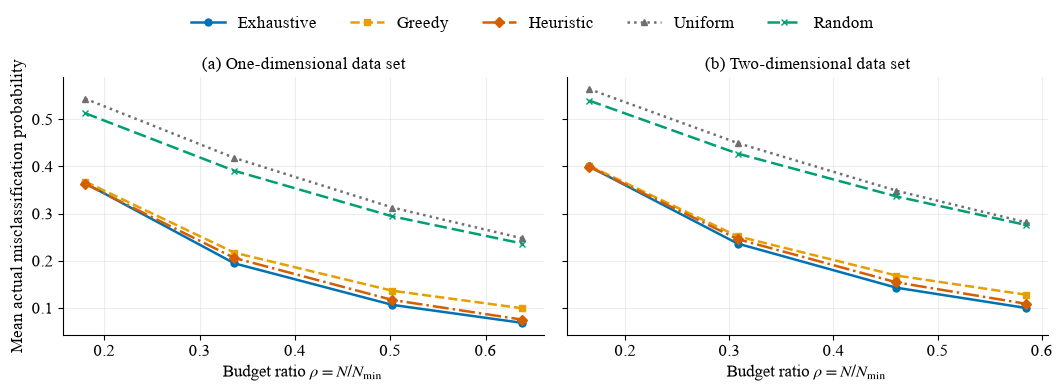

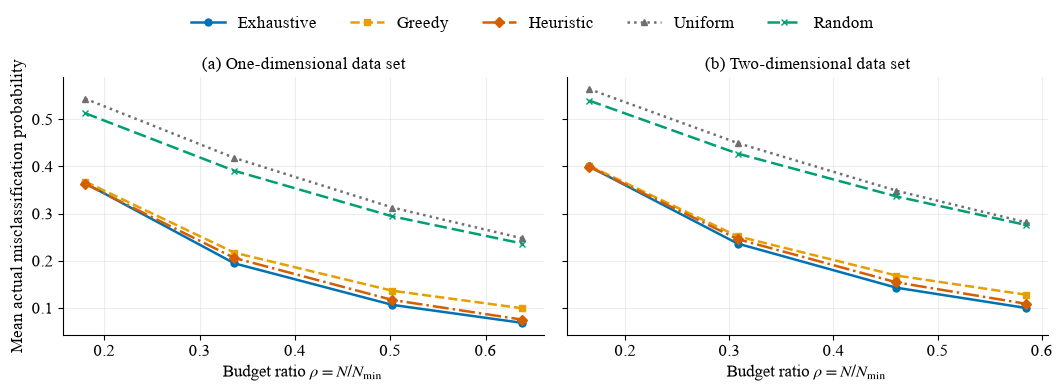

In [100]:
def plot_compact_actual_curves(records_by_dataset):
    figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.0), sharey=True)
    methods = COMPACT_METHODS
    for axis, records in zip(axes, by_dimension(records_by_dataset)):
        dimension = integer(records[0], "spatial_dimension")
        rows = curve_rows(records, methods, "_actual_error")
        for method in methods:
            y_key = f"{method}_actual_error"
            if y_key not in rows[0]:
                continue
            style = METHOD_STYLES[method]
            axis.plot(
                [row["budget_ratio"] for row in rows],
                [row[y_key] for row in rows],
                color=style["color"],
                linestyle=style["linestyle"],
                marker=style["marker"],
                linewidth=1.8,
                markersize=5.0,
                label=style["label"],
            )
        axis.set_title(DIMENSION_LABELS[dimension])
        axis.set_xlabel("Budget ratio $\\rho=N/N_{\\min}$")
        style_axis(axis)
    axes[0].set_ylabel("Mean actual misclassification probability")
    add_shared_legend(figure, axes, methods)
    figure.tight_layout(rect=(0, 0, 1, 0.90))
    return figure

compact_actual_curve_rows = [
    row
    for records in by_dimension(compact_actual_records)
    for row in curve_rows(records, COMPACT_METHODS, "_actual_error")
]
display(Markdown("### Figure Data: Compact Actual-Error Curves"))
display(Markdown(markdown_table(
    compact_actual_curve_rows,
    (
        ("Dimension", "dimension"),
        ("Budget level", "budget_level"),
        ("Budget ratio", "budget_ratio"),
        ("Exhaustive", "optimal_actual_error"),
        ("Greedy", "greedy_actual_error"),
        ("Heuristic", "heuristic_actual_error"),
        ("Uniform", "uniform_actual_error"),
        ("Random", "random_actual_error"),
    ),
    {
        "budget_level": lambda x: f"{int(x)}",
        "budget_ratio": lambda x: f"{float(x):.3f}",
        "optimal_actual_error": lambda x: f"{float(x):.4f}",
        "greedy_actual_error": lambda x: f"{float(x):.4f}",
        "heuristic_actual_error": lambda x: f"{float(x):.4f}",
        "uniform_actual_error": lambda x: f"{float(x):.4f}",
        "random_actual_error": lambda x: f"{float(x):.4f}",
    },
)))

figure_3 = plot_compact_actual_curves(compact_actual_records)
save_figure(figure_3, "figure_3_compact_actual_error_curves")
display_or_close(figure_3)

## Figure 4: Expanded Surrogate-Error Performance

This figure uses the saved expanded/scalable benchmark results, where exhaustive search is not included. It compares Greedy, Allocation + tree heuristic, Uniform, and Random using the surrogate objective from the original run.

### Figure Data: Expanded Surrogate-Error Curves

| Dimension | Budget level | Budget ratio | Greedy | Heuristic | Uniform | Random |
|---|---:|---:|---:|---:|---:|---:|
| 1D | 1 | 0.166 | 0.3685 | 0.3216 | 0.5941 | 0.5446 |
| 1D | 2 | 0.315 | 0.1873 | 0.1605 | 0.5062 | 0.4201 |
| 1D | 3 | 0.471 | 0.1096 | 0.0873 | 0.3976 | 0.3261 |
| 1D | 4 | 0.602 | 0.0755 | 0.0527 | 0.3269 | 0.2638 |
| 2D | 1 | 0.159 | 0.4061 | 0.3607 | 0.6098 | 0.5676 |
| 2D | 2 | 0.297 | 0.2232 | 0.1955 | 0.5253 | 0.4576 |
| 2D | 3 | 0.444 | 0.1375 | 0.1155 | 0.4301 | 0.3651 |
| 2D | 4 | 0.564 | 0.0986 | 0.0764 | 0.3610 | 0.3052 |

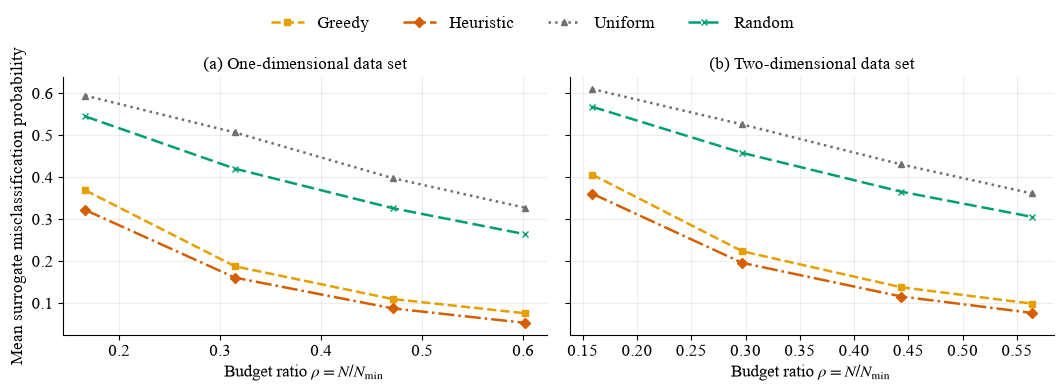

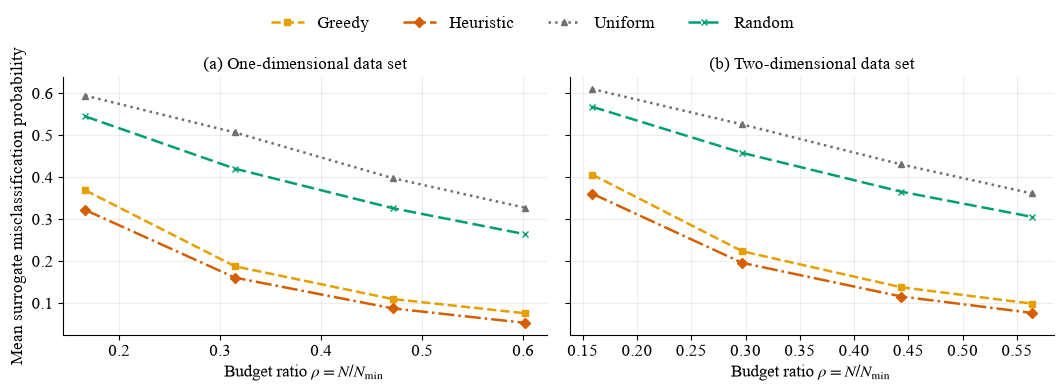

In [101]:
def plot_expanded_curves(records_by_dataset, suffix, ylabel):
    figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.0), sharey=True)
    methods = EXPANDED_METHODS
    for axis, records in zip(axes, by_dimension(records_by_dataset)):
        dimension = integer(records[0], "spatial_dimension")
        rows = curve_rows(records, methods, suffix)
        for method in methods:
            y_key = f"{method}{suffix}"
            if y_key not in rows[0]:
                continue
            style = METHOD_STYLES[method]
            axis.plot(
                [row["budget_ratio"] for row in rows],
                [row[y_key] for row in rows],
                color=style["color"],
                linestyle=style["linestyle"],
                marker=style["marker"],
                linewidth=1.8,
                markersize=5.0,
                label=style["label"],
            )
        axis.set_title(DIMENSION_LABELS[dimension])
        axis.set_xlabel("Budget ratio $\\rho=N/N_{\\min}$")
        style_axis(axis)
    axes[0].set_ylabel(ylabel)
    add_shared_legend(figure, axes, methods, ncol=4)
    figure.tight_layout(rect=(0, 0, 1, 0.90))
    return figure

expanded_surrogate_curve_rows = [
    row
    for records in by_dimension(expanded_surrogate_records)
    for row in curve_rows(records, EXPANDED_METHODS, "_error")
]
display(Markdown("### Figure Data: Expanded Surrogate-Error Curves"))
display(Markdown(markdown_table(
    expanded_surrogate_curve_rows,
    (
        ("Dimension", "dimension"),
        ("Budget level", "budget_level"),
        ("Budget ratio", "budget_ratio"),
        ("Greedy", "greedy_error"),
        ("Heuristic", "heuristic_error"),
        ("Uniform", "uniform_error"),
        ("Random", "random_error"),
    ),
    {
        "budget_level": lambda x: f"{int(x)}",
        "budget_ratio": lambda x: f"{float(x):.3f}",
        "greedy_error": lambda x: f"{float(x):.4f}",
        "heuristic_error": lambda x: f"{float(x):.4f}",
        "uniform_error": lambda x: f"{float(x):.4f}",
        "random_error": lambda x: f"{float(x):.4f}",
    },
)))

figure_4 = plot_expanded_curves(
    expanded_surrogate_records,
    "_error",
    "Mean surrogate misclassification probability",
)
save_figure(figure_4, "figure_4_expanded_surrogate_error_curves")
display_or_close(figure_4)

## Figure 5: Overall Surrogate-Error Performance

This figure combines the compact and extended surrogate-error results in one 2x2 panel. Columns show the one-dimensional and two-dimensional data sets; rows show the compact and extended benchmark collections.


### Figure Data: Compact and Extended Surrogate-Error Curves

| Data set | Dimension | Budget level | Budget ratio | Greedy | Heuristic | Uniform | Random |
|---|---|---:|---:|---:|---:|---:|---:|
| Compact | 1D | 1 | 0.180 | 0.3317 | 0.3034 | 0.5407 | 0.4894 |
| Compact | 1D | 2 | 0.337 | 0.1705 | 0.1517 | 0.4049 | 0.3579 |
| Compact | 1D | 3 | 0.502 | 0.1001 | 0.0808 | 0.2906 | 0.2606 |
| Compact | 1D | 4 | 0.639 | 0.0694 | 0.0491 | 0.2214 | 0.2047 |
| Compact | 2D | 1 | 0.165 | 0.3702 | 0.3443 | 0.5611 | 0.5204 |
| Compact | 2D | 2 | 0.308 | 0.2060 | 0.1892 | 0.4394 | 0.3988 |
| Compact | 2D | 3 | 0.460 | 0.1287 | 0.1110 | 0.3305 | 0.3059 |
| Compact | 2D | 4 | 0.585 | 0.0934 | 0.0741 | 0.2591 | 0.2448 |
| Extended | 1D | 1 | 0.166 | 0.3685 | 0.3216 | 0.5941 | 0.5446 |
| Extended | 1D | 2 | 0.315 | 0.1873 | 0.1605 | 0.5062 | 0.4201 |
| Extended | 1D | 3 | 0.471 | 0.1096 | 0.0873 | 0.3976 | 0.3261 |
| Extended | 1D | 4 | 0.602 | 0.0755 | 0.0527 | 0.3269 | 0.2638 |
| Extended | 2D | 1 | 0.159 | 0.4061 | 0.3607 | 0.6098 | 0.5676 |
| Extended | 2D | 2 | 0.297 | 0.2232 | 0.1955 | 0.5253 | 0.4576 |
| Extended | 2D | 3 | 0.444 | 0.1375 | 0.1155 | 0.4301 | 0.3651 |
| Extended | 2D | 4 | 0.564 | 0.0986 | 0.0764 | 0.3610 | 0.3052 |

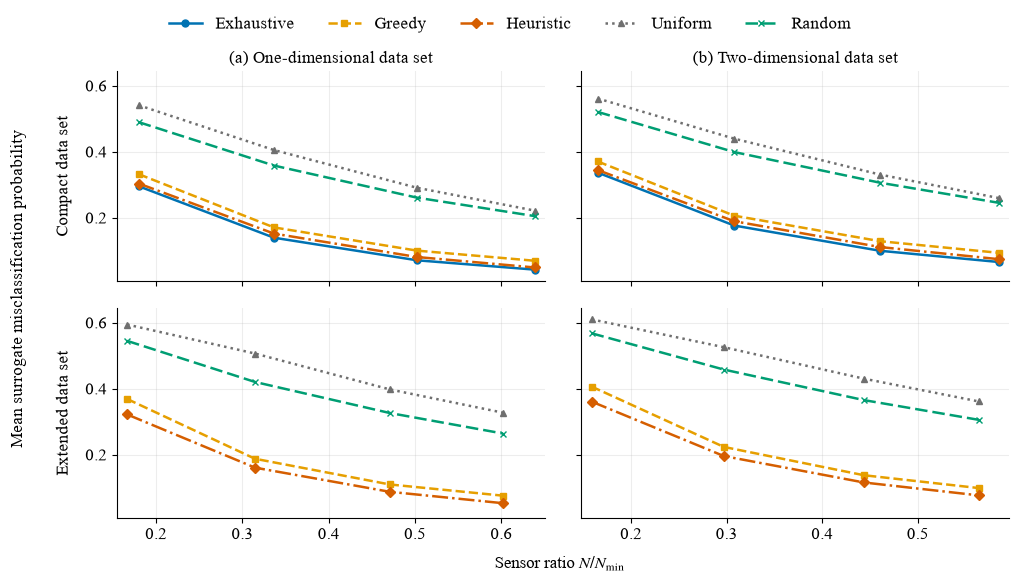

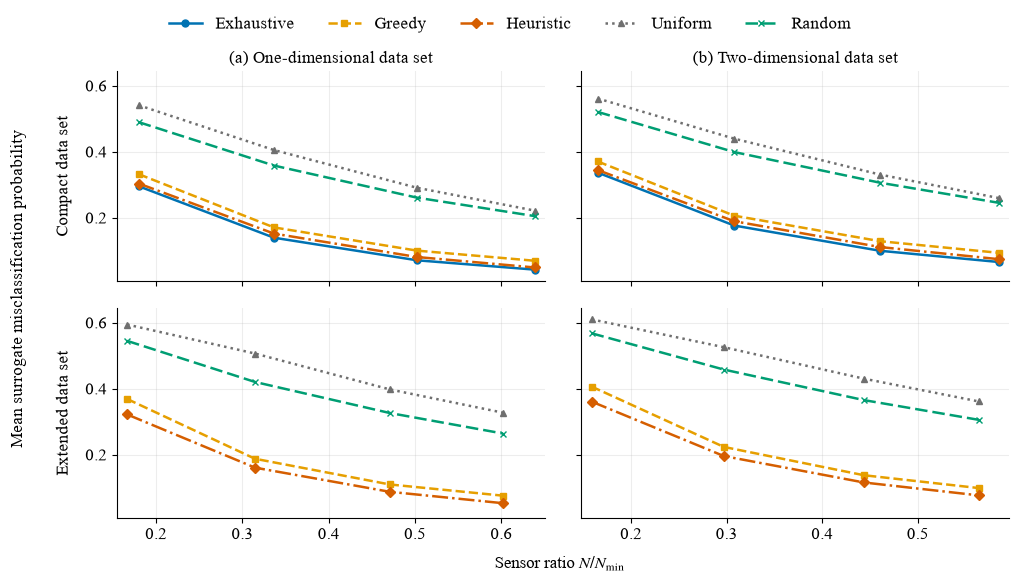

In [102]:
def plot_compact_extended_surrogate_curves(
    compact_records_by_dataset,
    extended_records_by_dataset,
):
    figure, axes = plt.subplots(
        2,
        2,
        figsize=(10.2, 5.8),
        sharex="col",
        sharey=True,
    )
    panel_rows = (
        ("Compact data set", compact_records_by_dataset, COMPACT_METHODS),
        ("Extended data set", extended_records_by_dataset, EXPANDED_METHODS),
    )
    column_titles = {
        1: "(a) One-dimensional data set",
        2: "(b) Two-dimensional data set",
    }

    for row_index, (row_label, records_by_dataset, methods) in enumerate(panel_rows):
        for axis, records in zip(axes[row_index], by_dimension(records_by_dataset)):
            dimension = integer(records[0], "spatial_dimension")
            rows = curve_rows(records, methods, "_error")
            for method in methods:
                y_key = f"{method}_error"
                if y_key not in rows[0]:
                    continue
                style = METHOD_STYLES[method]
                axis.plot(
                    [row["budget_ratio"] for row in rows],
                    [row[y_key] for row in rows],
                    color=style["color"],
                    linestyle=style["linestyle"],
                    marker=style["marker"],
                    linewidth=1.8,
                    markersize=5.0,
                    label=style["label"],
                )
            if row_index == 0:
                axis.set_title(column_titles[dimension])
            style_axis(axis)
        axes[row_index, 0].annotate(
            row_label,
            xy=(-0.125, 0.5),
            xycoords="axes fraction",
            ha="center",
            va="center",
            rotation=90,
            fontsize=12,
        )

    for axis in axes.ravel():
        axis.margins(x=0.025, y=0.06)
    figure.text(0.55, 0.025, r"Sensor ratio $N/N_{\min}$", ha="center", va="center")
    figure.text(
        0.018,
        0.50,
        "Mean surrogate misclassification probability",
        ha="center",
        va="center",
        rotation=90,
    )
    add_shared_legend(figure, axes.ravel(), COMPACT_METHODS, ncol=5)
    figure.subplots_adjust(
        left=0.115,
        right=0.990,
        bottom=0.105,
        top=0.875,
        wspace=0.085,
        hspace=0.130,
    )
    return figure

compact_extended_surrogate_curve_rows = []
for dataset_label, records_by_dataset, methods in (
    ("Compact", compact_surrogate_records, COMPACT_METHODS),
    ("Extended", expanded_surrogate_records, EXPANDED_METHODS),
):
    for records in by_dimension(records_by_dataset):
        for row in curve_rows(records, methods, "_error"):
            compact_extended_surrogate_curve_rows.append({
                "data_set": dataset_label,
                **row
            })

display(Markdown("### Figure Data: Compact and Extended Surrogate-Error Curves"))
display(Markdown(markdown_table(
    compact_extended_surrogate_curve_rows,
    (
        ("Data set", "data_set"),
        ("Dimension", "dimension"),
        ("Budget level", "budget_level"),
        ("Budget ratio", "budget_ratio"),
        ("Greedy", "greedy_error"),
        ("Heuristic", "heuristic_error"),
        ("Uniform", "uniform_error"),
        ("Random", "random_error"),
    ),
    {
        "budget_level": lambda x: f"{int(x)}",
        "budget_ratio": lambda x: f"{float(x):.3f}",
        "greedy_error": lambda x: f"{float(x):.4f}",
        "heuristic_error": lambda x: f"{float(x):.4f}",
        "uniform_error": lambda x: f"{float(x):.4f}",
        "random_error": lambda x: f"{float(x):.4f}",
    },
)))

figure_5 = plot_compact_extended_surrogate_curves(
    compact_surrogate_records,
    expanded_surrogate_records,
)
save_figure(figure_5, "figure_5_overall_surrogate_error_curves")
display_or_close(figure_5)


## Figure 6: Actual-Optimality Comparison

This figure compares the actual error of the surrogate-optimal compact solution with the actual-error optimum on the restricted compact validation sample.


### Figure Data: Actual-Optimality Comparison

| Dimension | Budget level | Budget ratio | Runs | Surrogate-optimal actual error | Actual-optimal actual error | Gap |
|---|---:|---:|---:|---:|---:|---:|
| 1D | 1 | 0.213 | 36 | 0.32303 | 0.31976 | 0.00327 |
| 1D | 2 | 0.399 | 36 | 0.15952 | 0.15482 | 0.00470 |
| 1D | 3 | 0.601 | 36 | 0.06892 | 0.06719 | 0.00173 |
| 1D | 4 | 0.762 | 35 | 0.03406 | 0.03346 | 0.00060 |
| 2D | 1 | 0.201 | 36 | 0.36507 | 0.35884 | 0.00623 |
| 2D | 2 | 0.368 | 36 | 0.19734 | 0.18647 | 0.01087 |
| 2D | 3 | 0.543 | 36 | 0.09171 | 0.08835 | 0.00336 |
| 2D | 4 | 0.699 | 35 | 0.04843 | 0.04754 | 0.00089 |

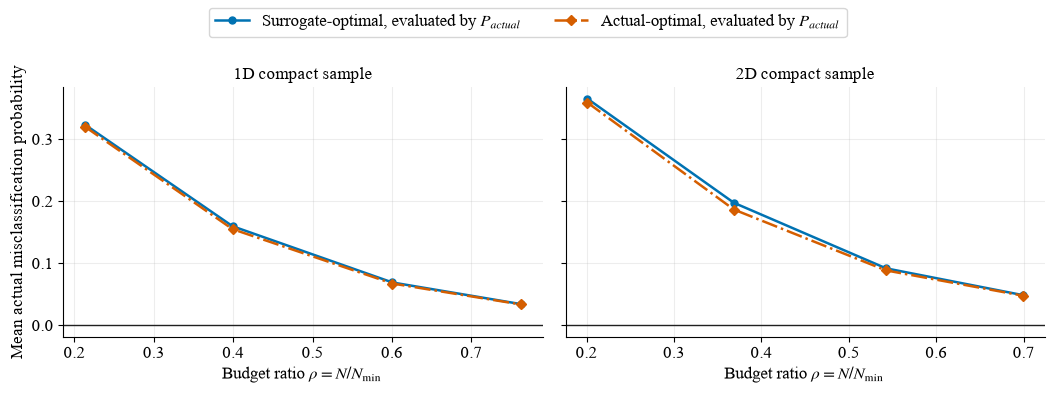

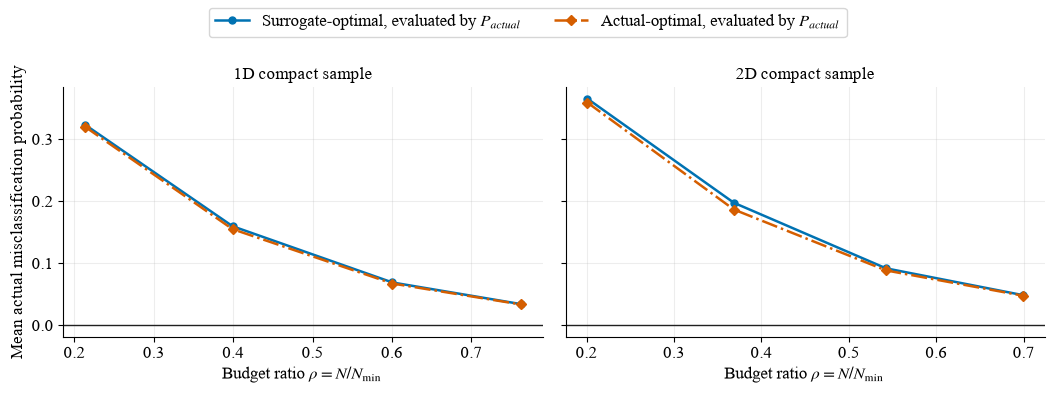

In [103]:
def actual_optimal_curve_rows(records_by_dataset):
    rows = []
    for records in by_dimension(records_by_dataset):
        dimension = f"{integer(records[0], 'spatial_dimension')}D"
        for level in sorted({integer(row, "budget_level") for row in records}):
            selected = [row for row in records if integer(row, "budget_level") == level]
            rows.append({
                "dimension": dimension,
                "budget_level": level,
                "budget_ratio": mean(value(row, "budget_fraction_of_N_min") for row in selected),
                "runs": len(selected),
                "surrogate_optimal_actual_error": mean(value(row, "surrogate_optimal_actual_error") for row in selected),
                "actual_optimal_actual_error": mean(value(row, "actual_optimal_actual_error") for row in selected),
                "actual_optimality_gap": mean(value(row, "actual_optimality_gap") for row in selected),
            })
    return rows


def plot_actual_optimality_comparison(rows):
    dimensions = sorted({row["dimension"] for row in rows})
    figure, axes = plt.subplots(1, len(dimensions), figsize=(10.8, 4.0), sharey=True)
    if len(dimensions) == 1:
        axes = [axes]
    styles = {
        "surrogate_optimal_actual_error": {
            "label": r"Surrogate-optimal, evaluated by $P_{actual}$",
            "color": METHOD_STYLES["optimal"]["color"],
            "linestyle": METHOD_STYLES["optimal"]["linestyle"],
            "marker": METHOD_STYLES["optimal"]["marker"],
        },
        "actual_optimal_actual_error": {
            "label": r"Actual-optimal, evaluated by $P_{actual}$",
            "color": METHOD_STYLES["heuristic"]["color"],
            "linestyle": METHOD_STYLES["heuristic"]["linestyle"],
            "marker": METHOD_STYLES["heuristic"]["marker"],
        },
    }
    for axis, dimension in zip(axes, dimensions):
        selected = [row for row in rows if row["dimension"] == dimension]
        for key, style in styles.items():
            axis.plot(
                [row["budget_ratio"] for row in selected],
                [row[key] for row in selected],
                color=style["color"],
                linestyle=style["linestyle"],
                marker=style["marker"],
                linewidth=1.8,
                markersize=5.0,
                label=style["label"],
            )
        axis.axhline(0.0, color="#202020", linewidth=1.0)
        axis.set_title(f"{dimension} compact sample")
        axis.set_xlabel(r"Budget ratio $\rho=N/N_{\min}$")
        style_axis(axis)
    axes[0].set_ylabel("Mean actual misclassification probability")
    handles, labels = axes[-1].get_legend_handles_labels()
    figure.legend(handles, labels, loc="outside upper center", ncol=len(labels))
    figure.tight_layout(rect=(0, 0, 1, 0.88))
    return figure


actual_optimal_budget_rows = actual_optimal_curve_rows(actual_optimal_records)
display(Markdown("### Figure Data: Actual-Optimality Comparison"))
display(Markdown(markdown_table(
    actual_optimal_budget_rows,
    (
        ("Dimension", "dimension"),
        ("Budget level", "budget_level"),
        ("Budget ratio", "budget_ratio"),
        ("Runs", "runs"),
        ("Surrogate-optimal actual error", "surrogate_optimal_actual_error"),
        ("Actual-optimal actual error", "actual_optimal_actual_error"),
        ("Gap", "actual_optimality_gap"),
    ),
    {
        "budget_level": lambda x: f"{int(x)}",
        "budget_ratio": lambda x: f"{float(x):.3f}",
        "runs": lambda x: f"{int(x)}",
        "surrogate_optimal_actual_error": lambda x: f"{float(x):.5f}",
        "actual_optimal_actual_error": lambda x: f"{float(x):.5f}",
        "actual_optimality_gap": lambda x: f"{float(x):.5f}",
    },
)))

figure_6 = plot_actual_optimality_comparison(actual_optimal_budget_rows)
save_figure(figure_6, "figure_6_actual_optimality_comparison")
display_or_close(figure_6)


## Figure 7: Heuristic Ablation

This figure uses the saved ablation summary from the extended analysis. It compares near-uniform and VND allocations under greedy and beam-search test ordering.


### Figure Data: Heuristic Ablation

| Dimension | Budget level | Budget ratio | Runs | Near-uniform + Greedy | VND allocation + Greedy | Near-uniform + Beam | VND allocation + Beam |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1D | 1 | 0.166 | 2700 | 0.5941 | 0.3673 | 0.5613 | 0.3216 |
| 1D | 2 | 0.315 | 2700 | 0.5062 | 0.1847 | 0.4716 | 0.1605 |
| 1D | 3 | 0.471 | 2692 | 0.3976 | 0.1020 | 0.3625 | 0.0873 |
| 1D | 4 | 0.602 | 2636 | 0.3269 | 0.0632 | 0.2956 | 0.0527 |
| 2D | 1 | 0.159 | 2700 | 0.6098 | 0.4057 | 0.5805 | 0.3607 |
| 2D | 2 | 0.297 | 2700 | 0.5253 | 0.2223 | 0.4938 | 0.1955 |
| 2D | 3 | 0.444 | 2695 | 0.4301 | 0.1333 | 0.3970 | 0.1155 |
| 2D | 4 | 0.564 | 2637 | 0.3610 | 0.0897 | 0.3293 | 0.0764 |

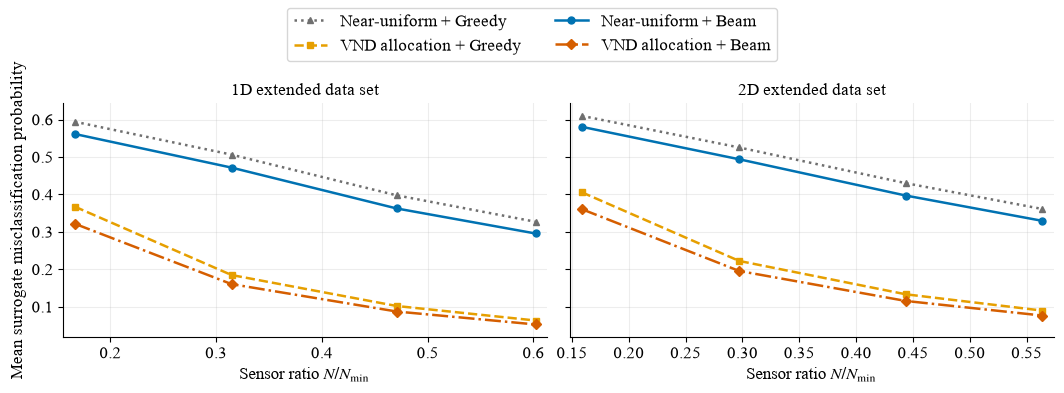

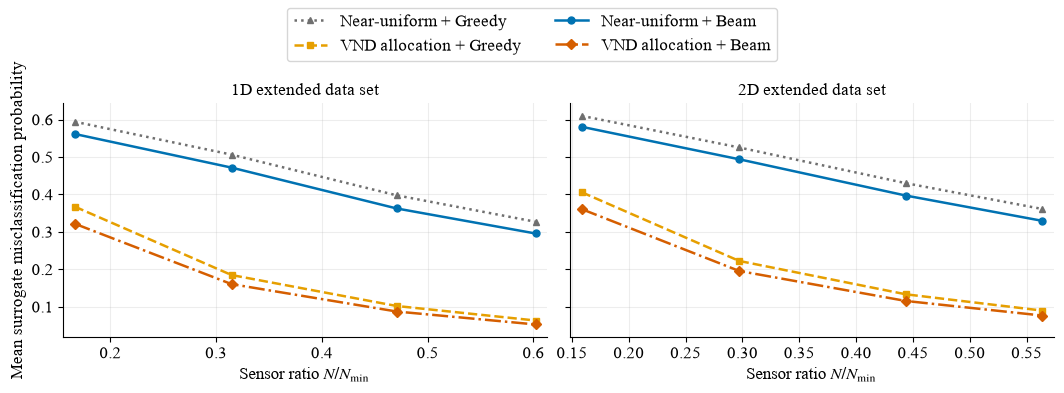

In [104]:
ABLATION_METHODS = (
    "Near-uniform + Greedy",
    "VND allocation + Greedy",
    "Near-uniform + Beam",
    "VND allocation + Beam",
)
ABLATION_METHOD_STYLES = {
    "Near-uniform + Greedy": {
        "color": METHOD_STYLES["uniform"]["color"],
        "linestyle": METHOD_STYLES["uniform"]["linestyle"],
        "marker": METHOD_STYLES["uniform"]["marker"],
    },
    "VND allocation + Greedy": {
        "color": METHOD_STYLES["greedy"]["color"],
        "linestyle": METHOD_STYLES["greedy"]["linestyle"],
        "marker": METHOD_STYLES["greedy"]["marker"],
    },
    "Near-uniform + Beam": {
        "color": METHOD_STYLES["optimal"]["color"],
        "linestyle": METHOD_STYLES["optimal"]["linestyle"],
        "marker": METHOD_STYLES["optimal"]["marker"],
    },
    "VND allocation + Beam": {
        "color": METHOD_STYLES["heuristic"]["color"],
        "linestyle": METHOD_STYLES["heuristic"]["linestyle"],
        "marker": METHOD_STYLES["heuristic"]["marker"],
    },
}


def plot_ablation_summary(rows):
    dimensions = sorted({row["dimension"] for row in rows})
    figure, axes = plt.subplots(1, len(dimensions), figsize=(10.8, 4.0), sharey=True)
    if len(dimensions) == 1:
        axes = [axes]
    for axis, dimension in zip(axes, dimensions):
        selected = sorted(
            [row for row in rows if row["dimension"] == dimension],
            key=lambda row: value(row, "budget_ratio"),
        )
        for method in ABLATION_METHODS:
            style = ABLATION_METHOD_STYLES[method]
            axis.plot(
                [value(row, "budget_ratio") for row in selected],
                [value(row, method) for row in selected],
                color=style["color"],
                linestyle=style["linestyle"],
                marker=style["marker"],
                linewidth=1.8,
                markersize=5.0,
                label=method,
            )
        axis.set_title(f"{dimension} extended data set")
        axis.set_xlabel(r"Sensor ratio $N/N_{\min}$")
        axis.margins(x=0.025, y=0.06)
        style_axis(axis)
    axes[0].set_ylabel("Mean surrogate misclassification probability")
    handles, labels = axes[-1].get_legend_handles_labels()
    figure.legend(handles, labels, loc="outside upper center", ncol=2)
    figure.tight_layout(rect=(0, 0, 1, 0.84))
    return figure


display(Markdown("### Figure Data: Heuristic Ablation"))
display(Markdown(markdown_table(
    ablation_budget_rows,
    (
        ("Dimension", "dimension"),
        ("Budget level", "budget_level"),
        ("Budget ratio", "budget_ratio"),
        ("Runs", "runs"),
        ("Near-uniform + Greedy", "Near-uniform + Greedy"),
        ("VND allocation + Greedy", "VND allocation + Greedy"),
        ("Near-uniform + Beam", "Near-uniform + Beam"),
        ("VND allocation + Beam", "VND allocation + Beam"),
    ),
    {
        "budget_level": lambda x: f"{int(float(x))}",
        "budget_ratio": lambda x: f"{float(x):.3f}",
        "runs": lambda x: f"{int(float(x))}",
        "Near-uniform + Greedy": lambda x: f"{float(x):.4f}",
        "VND allocation + Greedy": lambda x: f"{float(x):.4f}",
        "Near-uniform + Beam": lambda x: f"{float(x):.4f}",
        "VND allocation + Beam": lambda x: f"{float(x):.4f}",
    },
)))

figure_7 = plot_ablation_summary(ablation_budget_rows)
save_figure(figure_7, "figure_7_heuristic_ablation")
display_or_close(figure_7)


## Output Files

When `SAVE_FIGURES = True`, this notebook writes the following final files to `results/final_figures/`:

- `figure_1_compact_surrogate_error_curves.{pdf,png}`
- `figure_2_surrogate_vs_actual_error.{pdf,png}`
- `figure_3_compact_actual_error_curves.{pdf,png}`
- `figure_4_expanded_surrogate_error_curves.{pdf,png}`
- `figure_5_overall_surrogate_error_curves.{pdf,png}`
- `figure_6_actual_optimality_comparison.{pdf,png}`
- `figure_7_heuristic_ablation.{pdf,png}`


In [105]:
if SAVE_FIGURES:
    expected_files = [
        "figure_1_compact_surrogate_error_curves.pdf",
        "figure_1_compact_surrogate_error_curves.png",
        "figure_2_surrogate_vs_actual_error.pdf",
        "figure_2_surrogate_vs_actual_error.png",
        "figure_3_compact_actual_error_curves.pdf",
        "figure_3_compact_actual_error_curves.png",
        "figure_4_expanded_surrogate_error_curves.pdf",
        "figure_4_expanded_surrogate_error_curves.png",
        "figure_5_overall_surrogate_error_curves.pdf",
        "figure_5_overall_surrogate_error_curves.png",
        "figure_6_actual_optimality_comparison.pdf",
        "figure_6_actual_optimality_comparison.png",
        "figure_7_heuristic_ablation.pdf",
        "figure_7_heuristic_ablation.png",
    ]
    display(Markdown("### Saved Final Figures"))
    for filename in expected_files:
        print(OUTPUT_DIRECTORY / filename)
else:
    print("SAVE_FIGURES is False; no files were written.")


### Saved Final Figures

/Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/final_figures/figure_1_compact_surrogate_error_curves.pdf
/Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/final_figures/figure_1_compact_surrogate_error_curves.png
/Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/final_figures/figure_2_surrogate_vs_actual_error.pdf
/Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/final_figures/figure_2_surrogate_vs_actual_error.png
/Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/final_figures/figure_3_compact_actual_error_curves.pdf
/Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/final_fig